# Практическая работа № 4. Оценка качества данных

**Вариант 7** · `datasets::austres` и Stack Overflow Developer Survey 2022.

Проверяем девять типов аномалий и семь показателей качества по табл. 4.2–4.3 методички.
Внешний набор содержит одну волну опроса. В CSV 2022 из архива Kaggle варианта 7
после записи 68 809 обнаружен двоичный фрагмент. Для расчётов используем исходный
[публичный релиз 2022](https://github.com/StackExchange/Survey/tree/main/packages/archive/2022)
от Stack Overflow. Если есть проверенная локальная копия этой волны, укажите путь
в переменной окружения `ITAIOD_SURVEY_CSV`. Для локального словаря полей можно
задать `ITAIOD_SURVEY_SCHEMA`.

Выбранный объект наблюдения в опросе — опубликованная анкета, а в `austres` —
квартальная оценка численности. Аномалии могут пересекаться, поэтому их счётчики
показываются по отдельности. Для пропусков различаем обязательные, условно
ожидаемые и остальные поля.

## 1. Импорт и исходная схема

Значения CSV читаются как текст, чтобы проверка формата предшествовала
преобразованию в числа. Число полей считается по логическим CSV-записям,
с учётом запятых и переносов внутри кавычек. Колонки с вопросами описываются
по словарю релиза. Идентификатор и вычисленный показатель в словаре вопросов
дополняются вручную.

In [1]:
options(repr.matrix.max.rows = 85, timeout = max(180, getOption("timeout")))

# Получить локальную копию официального CSV. Возвращает путь к файлу.
resolve_csv <- function(variable, filename, local_name) {
  explicit_path <- Sys.getenv(variable)
  if (nzchar(explicit_path)) {
    if (!file.exists(explicit_path)) {
      stop("Путь из ", variable, " не существует: ", explicit_path)
    }
    return(explicit_path)
  }

  candidates <- c(local_name, file.path("..", "data", local_name))
  existing <- candidates[file.exists(candidates)]
  if (length(existing)) {
    return(existing[[1]])
  }

  source_root <- paste0(
    "https://media.githubusercontent.com/media/StackExchange/Survey/",
    "main/packages/archive/2022/"
  )
  target <- tempfile(fileext = ".csv")
  status <- download.file(paste0(source_root, filename, "?download=1"), target,
                          mode = "wb", quiet = TRUE)
  if (status != 0L) {
    stop("Загрузка не выполнена. Укажите локальный CSV через ", variable)
  }
  target
}

# Вернуть таблицу строк и флаги нарушения ширины записи.
read_survey <- function(path) {
  fields <- count.fields(path, sep = ",", quote = '"', comment.char = "")
  fields <- fields[!is.na(fields)]
  header <- names(read.csv(path, nrows = 0L, check.names = FALSE,
                           fileEncoding = "UTF-8-BOM"))
  if (length(fields) < 2L || length(header) < 2L ||
      fields[[1]] != length(header) || anyDuplicated(header)) {
    stop("Укажите полноценный CSV опроса 2022 с однозначными именами полей.")
  }
  widths <- fields[-1L]
  input_width <- max(length(header), widths)
  if (input_width > 2L * length(header)) {
    stop("В CSV есть сильно повреждённые записи. Проверьте исходный файл.")
  }
  input_names <- header
  if (input_width > length(header)) {
    input_names <- c(header, paste0("extra_", seq_len(input_width - length(header))))
  }

  raw <- read.csv(path, header = FALSE, skip = 1L, col.names = input_names,
                  colClasses = "character", check.names = FALSE, fill = TRUE,
                  fileEncoding = "UTF-8-BOM", na.strings = c("", "NA"))
  if (nrow(raw) != length(widths)) {
    stop("Количество записей CSV не совпало с результатом проверки структуры.")
  }
  list(data = raw[header], bad_width = widths != length(header))
}

csv_path <- resolve_csv("ITAIOD_SURVEY_CSV", "results.csv", "survey_results_public.csv")
schema_path <- resolve_csv(
  "ITAIOD_SURVEY_SCHEMA", "schema.csv", "survey_results_schema.csv"
)
survey_import <- read_survey(csv_path)
survey <- survey_import$data
survey_schema <- read.csv(schema_path, fileEncoding = "UTF-8-BOM")

population <- data.frame(
  Quarter = sprintf("%d-Q%d", floor(time(datasets::austres) + 1e-8),
                    cycle(datasets::austres)),
  Population = as.numeric(datasets::austres)
)
data.frame(
  Набор = c("austres", "Stack Overflow 2022"),
  Строки = c(nrow(population), nrow(survey)),
  Атрибуты = c(ncol(population), ncol(survey))
)

Набор,Строки,Атрибуты
<chr>,<int>,<int>
austres,89,2
Stack Overflow 2022,73268,79


In [2]:
numeric_fields <- c("ResponseId", "WorkExp", "CompTotal", "ConvertedCompYearly")
years_fields <- c("YearsCode", "YearsCodePro")
ordinal_fields <- c(
  "Age", "EdLevel", "OrgSize", "SOVisitFreq", "SOPartFreq", "SurveyLength",
  "SurveyEase", "PurchaseInfluence", paste0("Knowledge_", 1:7),
  paste0("Frequency_", 1:3), "TimeSearching", "TimeAnswering", "Onboarding"
)
multiple_fields <- c(
  grep("WorkedWith$|WorkWith$|^OpSys|^VCHosting", names(survey), value = TRUE),
  "Employment", "CodingActivities", "LearnCode", "LearnCodeOnline",
  "LearnCodeCoursesCert", "DevType", "BuyNewTool", "VersionControlSystem",
  "VCInteraction", "NEWSOSites", "Gender", "Sexuality", "Ethnicity",
  "Accessibility", "MentalHealth", "ProfessionalTech"
)
manual_labels <- c(
  ResponseId = "Идентификатор опубликованной анкеты",
  ConvertedCompYearly = "Годовое вознаграждение, пересчитанное в доллары США"
)
survey_names <- names(survey)
question_keys <- sub("(HaveWorkedWith|WantToWorkWith)$", "", survey_names)
question_keys[grepl("^OpSys", question_keys)] <- "OpSys"
question_keys[grepl("^VCHosting", question_keys)] <- "VCHosting"
descriptions <- survey_schema$question[match(question_keys, survey_schema$qname)]
descriptions <- trimws(gsub("[[:space:]]+", " ", gsub("<[^>]*>", " ", descriptions)))
has_manual <- survey_names %in% names(manual_labels)
descriptions[has_manual] <- unname(manual_labels[survey_names[has_manual]])
descriptions[is.na(descriptions)] <- survey_names[is.na(descriptions)]

field_type <- rep("Номинальный", length(survey_names))
field_type[survey_names %in% multiple_fields] <- "Множественный выбор"
field_type[survey_names %in% ordinal_fields] <- "Порядковый"
field_type[survey_names %in% numeric_fields] <- "Числовой"
field_type[survey_names %in% years_fields] <- "Число или граничная категория"
field_type[survey_names == "ResponseId"] <- "Идентификатор"
field_unit <- rep("—", length(survey_names))
field_unit[survey_names %in% c(years_fields, "WorkExp")] <- "лет"
field_unit[survey_names == "CompTotal"] <- "валюта Currency за период CompFreq"
field_unit[survey_names == "ConvertedCompYearly"] <- "USD/год"

population_dictionary <- data.frame(
  Атрибут = c("Quarter", "Population"),
  Описание = c("Отчётный квартал", "Численность населения Австралии"),
  Тип = c("Временной", "Числовой"),
  Единицы = c("квартал", "тыс. человек"),
  Формат = c("YYYY-Q1…Q4", "Десятичное число")
)
survey_dictionary <- data.frame(
  Атрибут = survey_names, Описание = descriptions, Тип = field_type,
  Единицы = field_unit, check.names = FALSE
)
survey_dictionary$Формат <- ifelse(
  survey_names %in% numeric_fields, "Десятичная запись",
  ifelse(survey_names %in% years_fields, "Целое 1–50 или граничный ответ",
         ifelse(survey_names %in% multiple_fields, "Ответы через ;", "Текст/категория"))
)
survey_dictionary$Формат[survey_names == "ResponseId"] <- "Положительное целое"
survey_dictionary$Формат[survey_names == "WorkExp"] <- "Неотрицательное целое"
survey_dictionary$Формат[survey_names == "Currency"] <- "Код ISO 4217 и название"
population_dictionary

Атрибут,Описание,Тип,Единицы,Формат
<chr>,<chr>,<chr>,<chr>,<chr>
Quarter,Отчётный квартал,Временной,квартал,YYYY-Q1…Q4
Population,Численность населения Австралии,Числовой,тыс. человек,Десятичное число


In [3]:
survey_dictionary

Атрибут,Описание,Тип,Единицы,Формат
<chr>,<chr>,<chr>,<chr>,<chr>
ResponseId,Идентификатор опубликованной анкеты,Идентификатор,—,Положительное целое
MainBranch,"Which of the following options best describes you today? Here, by ""developer"" we mean ""someone who writes code."" *",Номинальный,—,Текст/категория
Employment,Which of the following best describes your current employment status?,Множественный выбор,—,Ответы через ;
RemoteWork,Which best describes your current work situation?,Номинальный,—,Текст/категория
CodingActivities,Which of the following best describes the code you write outside of work? Select all that apply.,Множественный выбор,—,Ответы через ;
EdLevel,Which of the following best describes the highest level of formal education that you’ve completed? *,Порядковый,—,Текст/категория
LearnCode,How did you learn to code? Select all that apply.,Множественный выбор,—,Ответы через ;
LearnCodeOnline,What online resources do you use to learn to code? Select all that apply.,Множественный выбор,—,Ответы через ;
LearnCodeCoursesCert,What online courses or certifications do you use to learn to code? Select all that apply.,Множественный выбор,—,Ответы через ;


## 2. Правила поиска аномалий

Для `austres` покрытие сверяется с квартальной шкалой объекта R:
1971 Q2–1993 Q2. Текст справки `?austres` указывает другой период.
Расхождение метаданных само по себе не доказывает пропуска наблюдений.
Снижение населения между соседними кварталами фиксировалось бы как сигнал
для ручной проверки, поскольку в принципе оно возможно. Противоречие
фиксируется, если одному кварталу соответствуют разные оценки.

Для опроса эталон покрытия — последовательность идентификаторов 1–73 268
опубликованной волны. Она оценивает покрытие публичного файла. Для оценки
представительности среди всех разработчиков нужен другой источник.
Домен проверяется у идентификатора, категорий возраста и удалённой работы,
опыта, валюты, периода выплаты и оплаты. Семантические ограничения включают
неотрицательность чисел и наличие валюты и периода при опубликованной
пересчитанной оплате. Противоречия — несовпадающие анкеты с одним ID
и профессиональный стаж больше общего, если оба указаны числами.
Критерий недопустимого кортежа здесь операционный: корректно записанный ключ
выходит за рамки опубликованного реестра. Подлинность ответа респондента
по самому CSV проверить нельзя.

In [4]:
# Определить строки с одним и тем же ключом, но различным содержимым.
conflicting_keys <- function(key, rows) {
  known <- !is.na(key)
  unique_pairs <- !duplicated(rows)
  distinct_keys <- key[known & unique_pairs]
  conflicts <- distinct_keys[duplicated(distinct_keys)]
  known & key %in% conflicts
}

# Построить флаги ошибок домена среди непустых значений.
outside_format <- function(values, pattern) {
  !is.na(values) & !grepl(pattern, values, perl = TRUE)
}

# Учитывать повторы ключа после первой строки и точные повторы без ключа.
duplicate_rows <- function(key, rows) {
  (!is.na(key) & duplicated(key)) | (is.na(key) & duplicated(rows))
}

expected_quarters <- sprintf(
  "%d-Q%d", (1971L * 4L + 1L + 0:88) %/% 4L,
  (1971L * 4L + 1L + 0:88) %% 4L + 1L
)
population_key <- population$Quarter
population_value <- population$Population
population_checks <- list(
  lexical = rep(FALSE, nrow(population)),
  domain = outside_format(population_key, "^[0-9]{4}-Q[1-4]$") |
    (!is.na(population_value) & !is.finite(population_value)),
  irregular = list(Quarter = !is.na(population_key) &
                     population_key != trimws(population_key)),
  integrity = is.na(population_key) | is.na(population_value) |
    (!is.na(population_value) & population_value <= 0),
  contradiction = conflicting_keys(population_key, population),
  duplicate = duplicate_rows(population_key, population),
  invalid = !is.na(population_key) & !population_key %in% expected_quarters,
  missing = sum(is.na(population)),
  expected_cells = prod(dim(population)),
  absent = setdiff(expected_quarters, population_key),
  universe = length(expected_quarters)
)
data.frame(
  Кварталов = nrow(population),
  Снижений_относительно_предыдущего = sum(diff(population_value) < 0, na.rm = TRUE),
  Пропущенных_кварталов = length(population_checks$absent)
)

Кварталов,Снижений_относительно_предыдущего,Пропущенных_кварталов
<int>,<int>,<int>
89,0,0


In [5]:
survey_core <- c(
  "ResponseId", "MainBranch", "Country", "Age", "RemoteWork", "YearsCode",
  "YearsCodePro", "WorkExp", "Currency", "CompTotal", "CompFreq",
  "ConvertedCompYearly"
)
missing_columns <- setdiff(survey_core, names(survey))
if (length(missing_columns)) {
  stop("В CSV отсутствуют поля: ", paste(missing_columns, collapse = ", "))
}

clean <- lapply(survey[survey_core], trimws)
clean <- lapply(clean, function(values) replace(values, values %in% "", NA_character_))
number_pattern <- "^[+-]?([0-9]+([.][0-9]*)?|[.][0-9]+)([eE][+-]?[0-9]+)?$"
year_pattern <- "^(50|[1-4]?[0-9]|Less than 1 year|More than 50 years)$"
domain_errors <- list(
  ResponseId = outside_format(clean$ResponseId, "^[1-9][0-9]*$"),
  Age = !is.na(clean$Age) & !clean$Age %in% c(
    "Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
    "45-54 years old", "55-64 years old", "65 years or older", "Prefer not to say"
  ),
  RemoteWork = !is.na(clean$RemoteWork) & !clean$RemoteWork %in% c(
    "Fully remote", "Hybrid (some remote, some in-person)", "Full in-person"
  ),
  YearsCode = outside_format(clean$YearsCode, year_pattern),
  YearsCodePro = outside_format(clean$YearsCodePro, year_pattern),
  WorkExp = outside_format(clean$WorkExp, "^[+-]?[0-9]+$"),
  Currency = outside_format(clean$Currency, "^[A-Z]{3}[[:space:]]+[^[:space:]].*$"),
  CompTotal = outside_format(clean$CompTotal, number_pattern),
  CompFreq = !is.na(clean$CompFreq) & !clean$CompFreq %in% c("Weekly", "Monthly", "Yearly"),
  ConvertedCompYearly = outside_format(clean$ConvertedCompYearly, number_pattern)
)
irregular <- lapply(survey, function(values) {
  !is.na(values) & trimws(values) != values
})
currency_tab <- grepl("^[A-Z]{3}\t", clean$Currency)
currency_space <- grepl("^[A-Z]{3} ", clean$Currency)
if (any(currency_tab) && any(currency_space)) {
  less_used_separator <- if (sum(currency_tab) < sum(currency_space)) {
    currency_tab
  } else {
    currency_space
  }
  irregular$Currency <- irregular$Currency | less_used_separator
}
key <- replace(clean$ResponseId, domain_errors$ResponseId, NA_character_)
expected_ids <- as.character(seq_len(73268L))

# Строки без числового ответа остаются неопределёнными для числовых правил.
experience <- suppressWarnings(as.numeric(clean$YearsCode))
pro_experience <- suppressWarnings(as.numeric(clean$YearsCodePro))
work_exp <- suppressWarnings(as.numeric(clean$WorkExp))
pay <- suppressWarnings(as.numeric(clean$CompTotal))
yearly_pay <- suppressWarnings(as.numeric(clean$ConvertedCompYearly))
known_pay <- !is.na(clean$ConvertedCompYearly)
mandatory <- c("ResponseId", "MainBranch")
missing_mandatory <- sum(vapply(clean[mandatory], function(x) sum(is.na(x)), 0L))
pay_inputs <- c("Currency", "CompTotal", "CompFreq")
missing_pay_inputs <- sum(vapply(clean[pay_inputs], function(x) {
  sum(known_pay & is.na(x))
}, 0L))

survey_checks <- list(
  lexical = survey_import$bad_width,
  domain = Reduce(`|`, domain_errors),
  irregular = irregular,
  integrity = is.na(key) | is.na(clean$MainBranch) |
    (!is.na(work_exp) & work_exp < 0) | (!is.na(pay) & pay < 0) |
    (!is.na(yearly_pay) & yearly_pay < 0) |
    (known_pay & (is.na(clean$Currency) | is.na(clean$CompFreq) | is.na(clean$CompTotal))),
  contradiction = conflicting_keys(key, survey) |
    (!is.na(experience) & !is.na(pro_experience) & pro_experience > experience),
  duplicate = duplicate_rows(key, survey),
  invalid = !is.na(key) & !key %in% expected_ids,
  missing = missing_mandatory + missing_pay_inputs,
  expected_cells = length(mandatory) * nrow(survey) + length(pay_inputs) * sum(known_pay),
  absent = setdiff(expected_ids, key),
  universe = length(expected_ids)
)

data.frame(
  Поле = survey_names,
  Пустые_ячейки = vapply(survey, function(x) sum(is.na(x) | trimws(x) == ""), 0L),
  Нарушения_домена = vapply(survey_names, function(field) {
    if (field %in% names(domain_errors)) sum(domain_errors[[field]]) else NA_integer_
  }, 0L),
  Нерегулярные_значения = vapply(irregular, sum, 0L),
  row.names = NULL
)

Поле,Пустые_ячейки,Нарушения_домена,Нерегулярные_значения
<chr>,<int>,<int>,<int>
ResponseId,0,0,0
MainBranch,0,NA,0
Employment,1559,NA,0
RemoteWork,14310,0,0
CodingActivities,14369,NA,0
EdLevel,1697,NA,0
LearnCode,1688,NA,0
LearnCodeOnline,22583,NA,0
LearnCodeCoursesCert,43879,NA,0


## 3. Счётчики и показатели

Полнота — доля представленных ключей в заданном реестре. Достоверность
оценивается по ограничениям целостности и допустимости ключа.
Соответствие схеме учитывает ширину CSV-записи и проверенные форматы доменов.
Согласованность — доля строк, у которых одновременно верна схема, нет
нерегулярности и нет противоречия. Однородность — доля столбцов без
нерегулярных значений. Плотность приведена в смысле методички как доля
пропусков среди ячеек, которые должны быть заполнены. Уникальность —
доля строк после исключения повторов ключа. Доля повторов равна её
дополнению до 1.

In [6]:
# Вычислить счётчики аномалий с единицами подсчёта.
anomaly_counts <- function(checks) {
  c(
    "Лексические ошибки" = sum(checks$lexical),
    "Ошибки формата домена" = sum(checks$domain),
    "Нерегулярность" = sum(Reduce(`|`, checks$irregular)),
    "Нарушения целостности" = sum(checks$integrity),
    "Противоречия" = sum(checks$contradiction),
    "Дубликаты" = sum(checks$duplicate),
    "Недопустимые кортежи" = sum(checks$invalid),
    "Отсутствующие значения" = checks$missing,
    "Отсутствующие кортежи" = length(checks$absent)
  )
}

# Вычислить доли по формулам раздела «Очистка данных и качество данных».
quality_scores <- function(checks, attribute_count) {
  schema_error <- checks$lexical | checks$domain
  inconsistent <- schema_error | Reduce(`|`, checks$irregular) | checks$contradiction
  c(
    "Полнота" = 1 - length(checks$absent) / checks$universe,
    "Достоверность" = mean(!(checks$integrity | checks$invalid)),
    "Согласованность" = mean(!inconsistent),
    "Соответствие схеме" = mean(!schema_error),
    "Однородность" = 1 - sum(vapply(checks$irregular, any, FALSE)) / attribute_count,
    "Плотность пропусков" = checks$missing / checks$expected_cells,
    "Уникальность" = mean(!checks$duplicate)
  )
}

counts <- cbind(
  austres = anomaly_counts(population_checks),
  Survey_2022 = anomaly_counts(survey_checks)
)
scores <- cbind(
  austres = quality_scores(population_checks, ncol(population)),
  Survey_2022 = quality_scores(survey_checks, ncol(survey))
)
data.frame(
  Аномалия = rownames(counts), counts,
  Единица = c(rep("строк", 7), "ячеек", "ключей"),
  row.names = NULL, check.names = FALSE
)

Аномалия,austres,Survey_2022,Единица
<chr>,<int>,<int>,<chr>
Лексические ошибки,0,0,строк
Ошибки формата домена,0,1,строк
Нерегулярность,0,14983,строк
Нарушения целостности,0,0,строк
Противоречия,0,499,строк
Дубликаты,0,0,строк
Недопустимые кортежи,0,0,строк
Отсутствующие значения,0,0,ячеек
Отсутствующие кортежи,0,0,ключей


In [7]:
data.frame(Показатель = rownames(scores), round(100 * scores, 4),
           row.names = NULL, check.names = FALSE)

Показатель,austres,Survey_2022
<chr>,<dbl>,<dbl>
Полнота,100,100.0000
Достоверность,100,100.0000
Согласованность,100,79.0004
Соответствие схеме,100,99.9986
Однородность,100,96.2025
Плотность пропусков,0,0.0000
Уникальность,100,100.0000


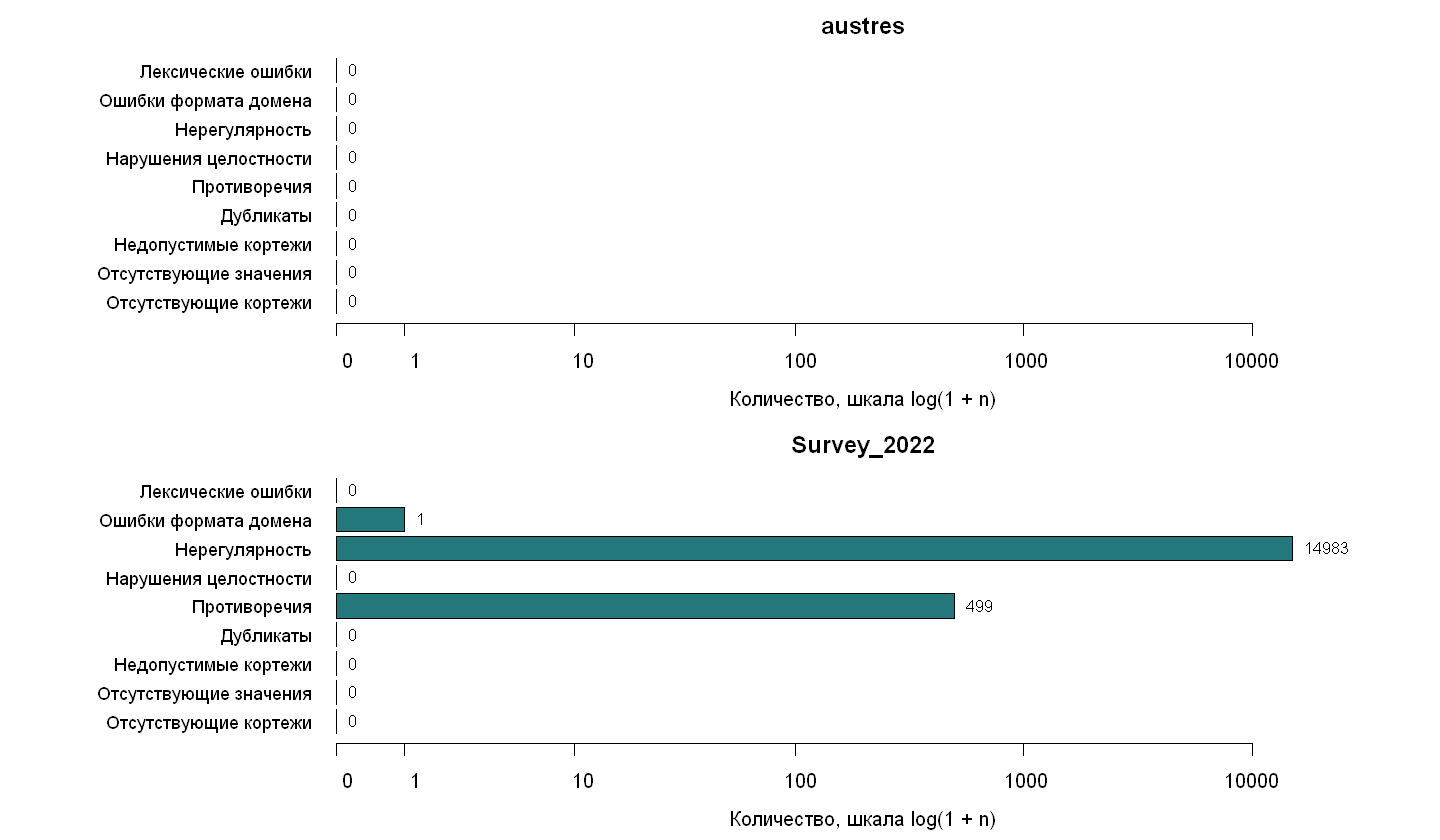

In [8]:
# Показать и нулевые, и редкие аномалии на шкале log(1 + n).
options(repr.plot.width = 12, repr.plot.height = 7)
axis_counts <- c(0, 1, 10, 100, 1000, 10000, 100000)
visible_ticks <- axis_counts[axis_counts <= max(10, 2 * max(counts))]
old_par <- par(mfrow = c(2, 1), mar = c(4, 14, 2, 2))
for (dataset in colnames(counts)) {
  values <- rev(counts[, dataset])
  mids <- barplot(
    log1p(values), horiz = TRUE, axes = FALSE, las = 1, cex.names = 0.9,
    main = dataset, col = "#24777B", xlim = c(0, max(log1p(counts)) + 1)
  )
  axis(1, at = log1p(visible_ticks), labels = format(visible_ticks, scientific = FALSE))
  mtext("Количество, шкала log(1 + n)", side = 1, line = 2.6)
  text(log1p(values), mids, labels = values, pos = 4, cex = 0.8)
}
par(old_par)

In [9]:
cat(sprintf(
  "austres: покрыто %.1f%% ожидаемых кварталов, доля повторов %.2f%%.\n",
  100 * scores["Полнота", "austres"],
  100 * (1 - scores["Уникальность", "austres"])
))
cat(sprintf(
  paste0("Survey 2022: покрыто %.2f%% ключей публичного реестра. ",
         "Согласованность по проверенным правилам — %.2f%%, ",
         "пропуски в ожидаемых полях — %.2f%%.\n"),
  100 * scores["Полнота", "Survey_2022"],
  100 * scores["Согласованность", "Survey_2022"],
  100 * scores["Плотность пропусков", "Survey_2022"]
))
all_blank <- sum(vapply(survey, function(x) sum(is.na(x) | trimws(x) == ""), 0L))
cat(sprintf(
  "Во всех 79 полях анкеты пусты %.2f%% ячеек, включая необязательные ответы.\n",
  100 * all_blank / prod(dim(survey))
))


austres: покрыто 100.0% ожидаемых кварталов, доля повторов 0.00%.


Survey 2022: покрыто 100.00% ключей публичного реестра. Согласованность по проверенным правилам — 79.00%, пропуски в ожидаемых полях — 0.00%.


Во всех 79 полях анкеты пусты 28.43% ячеек, включая необязательные ответы.


## Вывод

Для квартального ряда ключи и ожидаемое покрытие определяются календарём.
У опроса полнота по опубликованным анкетам и пригодность конкретного атрибута
для анализа — разные свойства. Для анализа оплаты сначала отберите записи
с пригодными значениями `Currency`, `CompFreq`, `CompTotal` и
`ConvertedCompYearly`. Неопрошенные и необязательные поля не следует считать
ошибками без учёта маршрута анкеты. Проверка стажа помечает подозрительные
ответы для анализа чувствительности. Автоматически исправлять их без
подтверждения респондента нельзя.

Методика: ПР № 4, разделы «Аномалии данных» и «Очистка данных и качество
данных», таблицы 4.2–4.3. Размер опубликованной волны указан в
[результатах опроса 2022](https://survey.stackoverflow.co/2022/).